
**Індустрія:** Онлайн магазин одягу (E-commerce)

**Аудиторія:** Мас-маркет; клієнти, які купують одяг різних брендів в одному місці

**Вирішення пробелими:** Збільшення клієнтів, які повертаються та роблять покупку (Repeat Customer Rate)  

**Метрика:** Скільки клієтів зроблять повторну поекпку за якийсь період часу Repeat Customer Rate (RCR). Рахується за формулою:

$$\text{Repeat Customer Rate}=\frac{\text{Number of Return Customers}}{\text{Total Number of Customers}}$$


**Поточне значення метрики:** історично для мас-маркет онлайн магазинів одягу RCR становить 25%-30%. Я вибрав $\mu_0 = 0.28$. Це нижче середнього історичного показника, тому є місце для реалічиного збільшення RCR.


---


**Суть A/B тесту:** Компанія дає знижку 10% при купівлі товару, яка активується через тиждень після покупки та діє 1 календарний місяць, щоб скористатися знижкою. Можливо люди не купують одяг так часто, тому 10% знижки не збільшить кількість покупців, які повертаються або на приклад 10% за мало, щоб мотивувати людей повертатися. Інший варіант, що 10% знижки все таки збільшать RCR.

**Визначення гіпотез:**
> $H_0$: $μ = 0.28$ \
> $H_1$: $μ > 0.28$

**Одностороній чи двохстороній тест:** Викорстовуємо лівосторонній тест, оскільки ми очікуємо тільки можливе збільшення.


**Вибір $\alpha$:** Я вибрав $\alpha = 0.05$, оскільки це стандарт. Це компроміс між помилкою I роду та II роду. Якщо обрати занадто мало $\alpha$, це збільшує ймовірність помилки II роду, а якщо обрати завелику $\alpha$ збільшитья ймовірність помилки I роду.













**Справжня ймовірність та розмір вибірки:** Нехай за тиждень у магазина було 1000 покупців (N = 1000) та справня ймовірність 0.32 (latent mu = 0.32)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib_inline
from scipy.stats import binom, binomtest, bernoulli

In [ ]:
# Задаємо latent_mu (справня ймовірність) та розмір вибірки. Створюємо вибірку
# рахуємо кількість успіхів
np.random.seed(42)
latent_mu = 0.32
N = 1000
sample = bernoulli.rvs(p = latent_mu, size = N)
q = np.sum(sample)


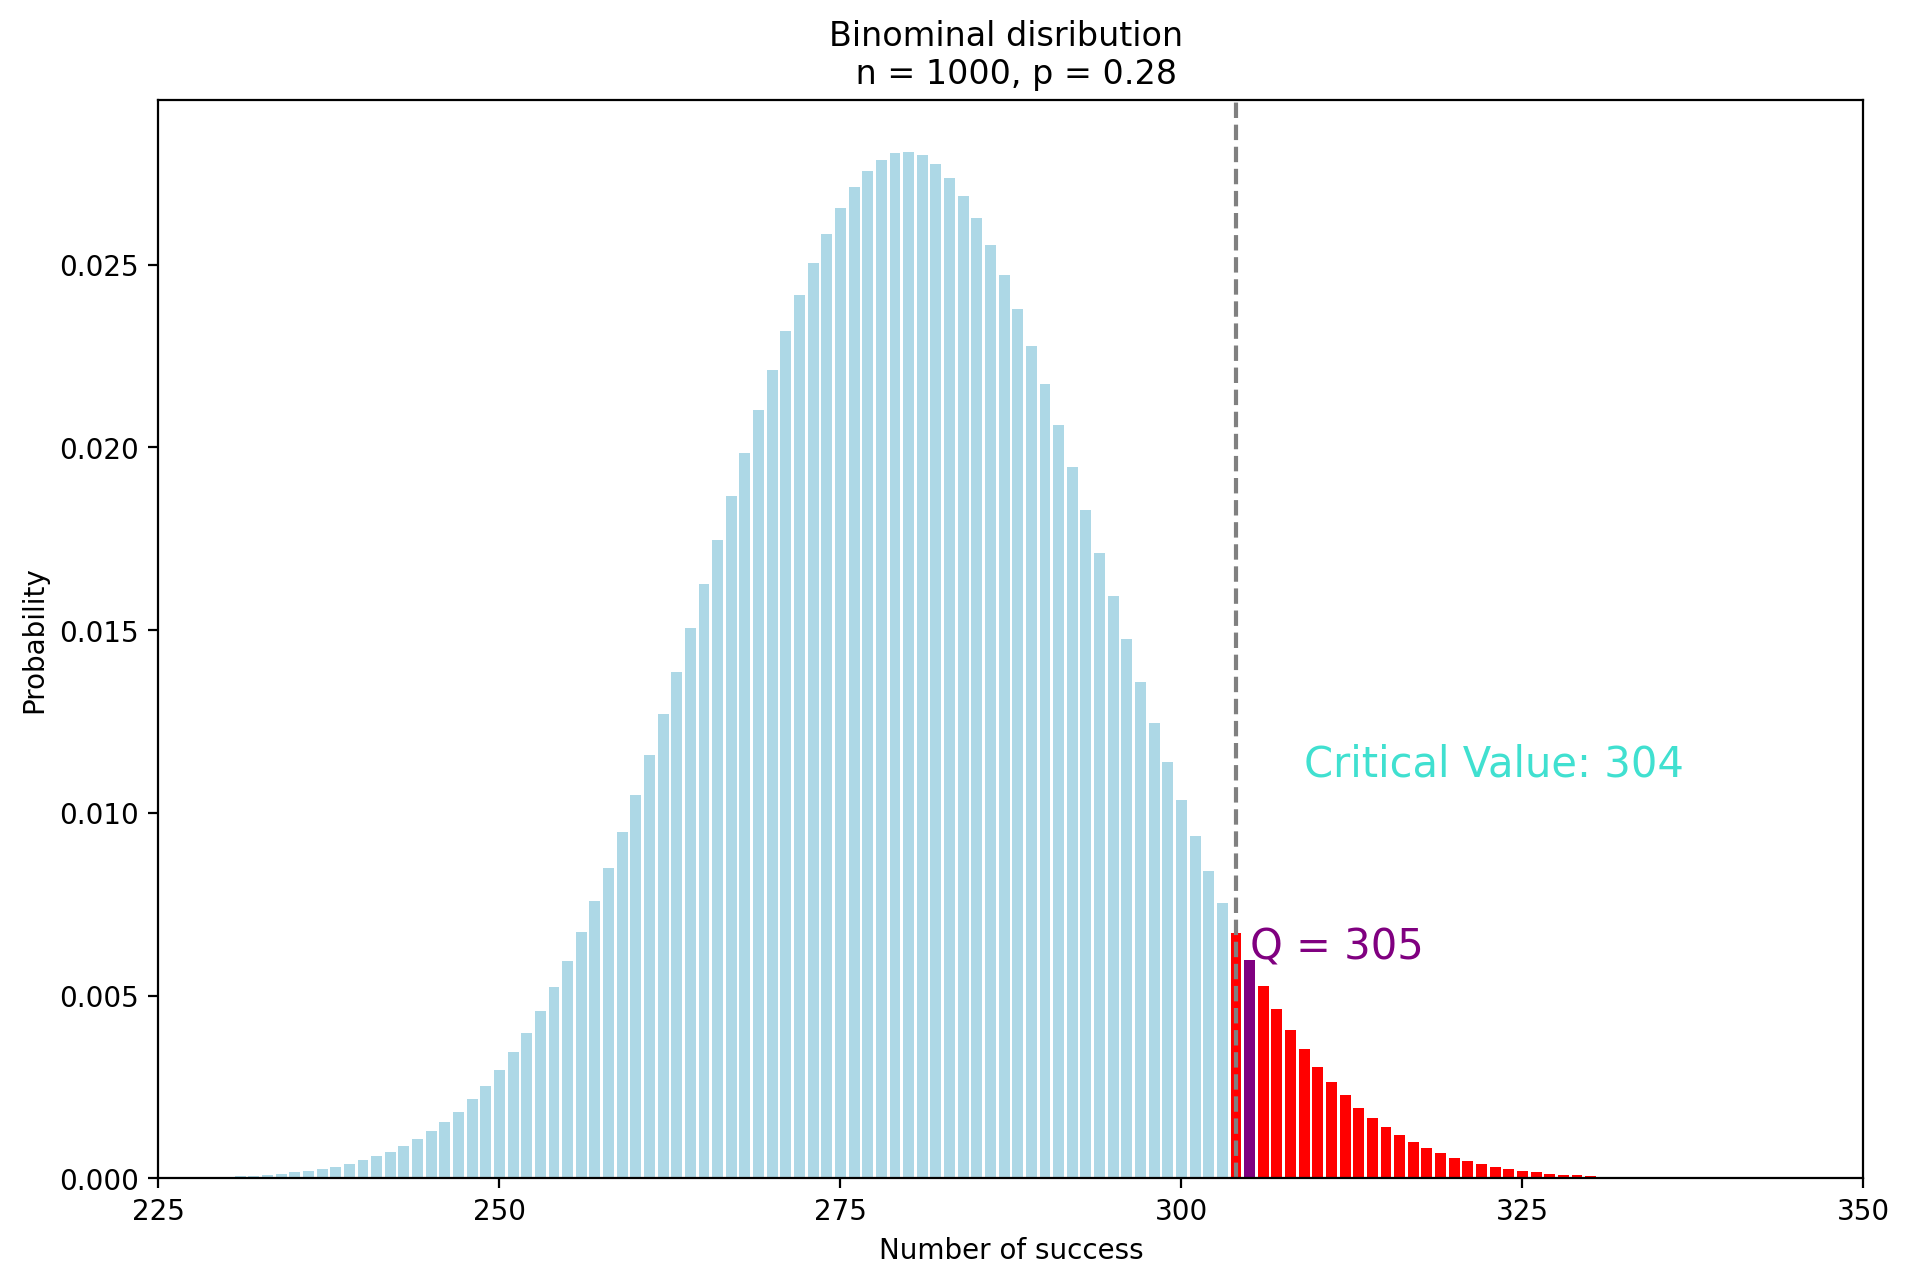

In [ ]:
# Задаємо mu та alpha
mu = 0.28
alpha = 0.05

# Створюємо вісь X потім створюємо PMF, Binom (вісь Y) за допомогю binom.pmf
x_grid = np.arange(N + 1)
y_grid = binom.pmf(p = mu, k = x_grid, n = N)

# Рахуємо critical value
critical_value = int(binom.ppf(1 - alpha, N, mu)) + 1

# Робимо інший колір правіше від critical value та інший колір для
crit_reg = x_grid >= critical_value
colors = np.where(crit_reg, "red", "lightblue")
colors[q] = "purple"

# Стіорюємо пустий графік та додаємо bar plot PMF, Binom (вісь Y)
matplotlib_inline.backend_inline.set_matplotlib_formats('retina')
fig, ax = plt.subplots()
ax.bar(x = x_grid, height = y_grid, color = colors)

# Додаємо вертикальну лінію, де critical value
ax.axvline(critical_value, color = "grey", linestyle = "--")

# Задаємо заголовок, заголовки вісям, xticks, set_xlim
fig.set_size_inches(11, 7)
ax.set_xlabel("Number of success")
ax.set_ylabel("Probability")
ax.set_title(f"Binominal disribution \n n = {N}, p = {mu}")
ax.set_xlim(225, 350)
ax.set_xticks(np.arange(225, 375, 25))

# Створюємо текст "Critical Value: {critical_value}"
ax.text(critical_value + 5, 0.011, f"Critical Value: {critical_value}", fontsize = 15, color = "turquoise")

ax.text(q, 0.006, f"Q = {q}", fontsize = 15, color = "purple")

# Створюємо легенду, але не використовуємо
#legend_elements = [Line2D([0], [0], color="lightblue", lw=3, label="PMF, Binom(0.28, 1000)"),
#                   Line2D([0], [0], color="grey", lw=3, linestyle="--", label=f"Critical value {critical_value}")]

#ax.legend(handles=legend_elements, loc="center right", fontsize=14)

plt.show()

Порахуємо p-value спочатку за допомогою binom.cdf, а потім за допомогю binomtest

**Як можна побачити p-value однакові**

**Інтерпретації p-value:**

* Формально: p-value - це ймовірність отримати значення успішиних ексерементів більше ніж ми отримали або таке ж саме.

* Для бізнесу: p-value показує зміни, які бачимо це наслідок змін або випадковості. Якщо ми повторимо зміни, чи залищшаться зміни?
>Якщо p-value < 0.05 результата не випадковістю, але все ще можемо бути помилка роду.\
>Якщо p-value > 0.05 результата випадковістю.

In [ ]:
# Шукаємо p-value за допомогою cdf
p_value = 1 - binom.cdf(q - 1, N, mu)
if p_value <= 0.05:
    message = f"p-value = {p_value:.3f} <= 0.05"
else:
    message = f"p-value = {p_value:.3f} >= 0.05"
print(message)

p-value = 0.043 <= 0.05


In [ ]:
# Шукаємо p-value за допомогою binomtest
result = binomtest(k = q, n = N, p = mu, alternative='greater')
p_value = result.pvalue
if p_value <= 0.05:
    message = f"p-value = {p_value:.3f} <= 0.05"
else:
    message = f"p-value = {p_value:.3f} >= 0.05"
print(message)


p-value = 0.043 <= 0.05


> Помилка I роду помилкове відхилення $H_0$ μ \
> Помилка II роду не відхилення $H_0$, коли треба

Зменшуючи $\alpha$ (Type I error / FPR) ми збільшуємо $\beta$ (Type II error FNR) і навпаки для фіксованого розміру виборки N. Тому важливо найти компроміс між $\alpha$ і $\beta$. Можна побачити це на грфіку, зменшуючи $\alpha$, ми змешуємо синю зону, проте збільшуємо синю (Type II error FNR).


**Вибір альтернативного $\mu$** Я вибрав альтернативного $\mu$ = 0.33, оскільки він не виходить з історичного та та очікувати приросту в 5p.p. я вважаю реалістично. Виходить MDE = 0.05

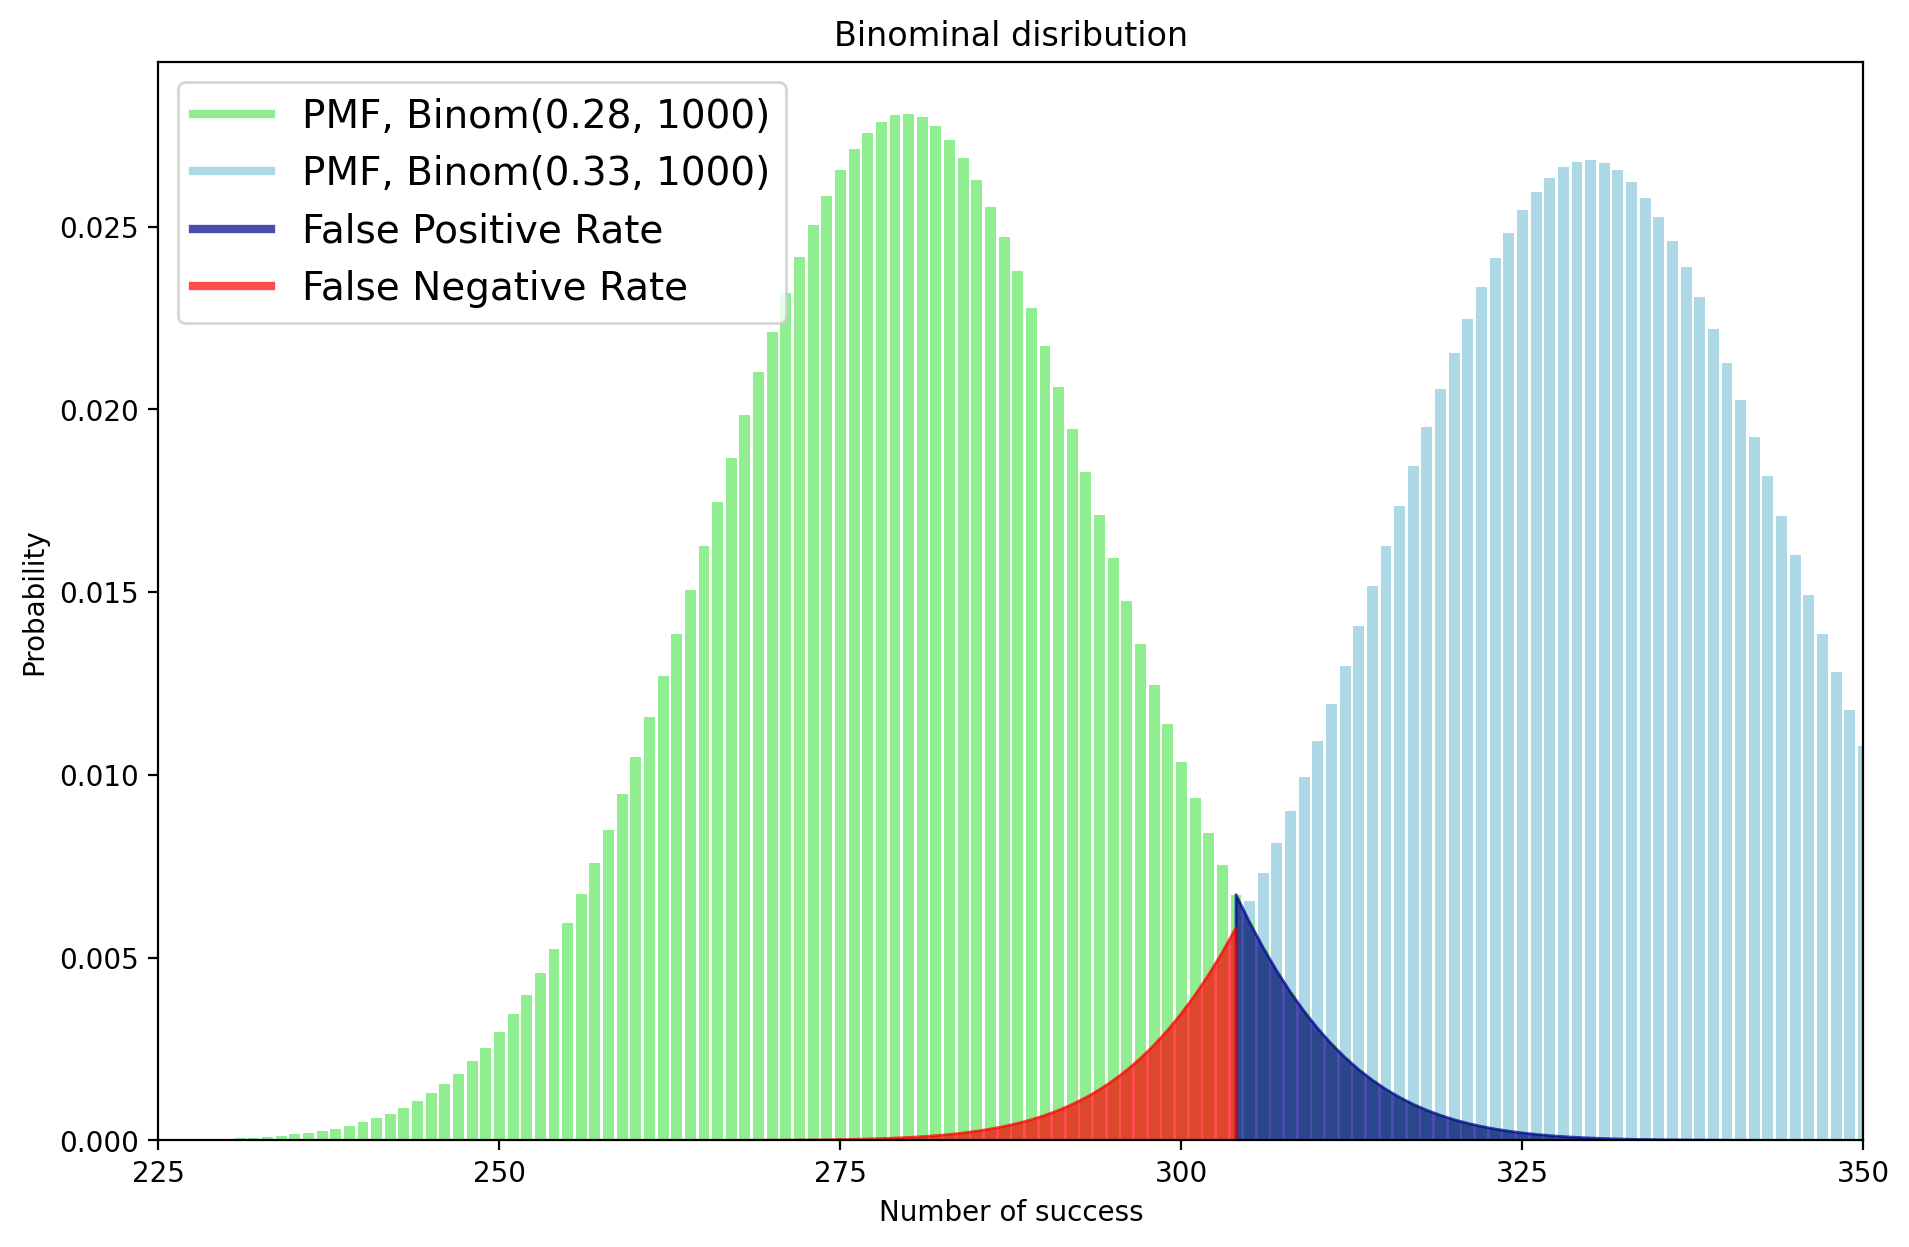

In [ ]:
# Задаємо mu, alpha та
mu = 0.28
mu_alt = 0.33
alpha = 0.05

# Створюємо вісь X потім створюємо PMF, Binom (вісь Y) для mu та mu_alt за допомогю binom.pmf
x_grid = np.arange(N + 1)
y_grid = binom.pmf(p = mu, k = x_grid, n = N)
y_grid_alt = binom.pmf(p = mu_alt, k = x_grid, n = N)

# Рахуємо critical value
critical_value = int(binom.ppf(1 - alpha, N, mu)) + 1

# Робимо різні кольори для двох PMF, Binom та інші кольори для alpha та beta
crit_reg = x_grid >= critical_value
colors = np.where(crit_reg, "red", "lightblue")
colors_alt = np.where(~crit_reg, "lightgreen", "darkturquoise")

# Створюємо пустий графік потім додаємо до нього два PMF, Binom
fig, ax = plt.subplots(figsize = (11, 7))
ax.bar(x = x_grid, height = y_grid_alt, color = "lightblue")
ax.bar(x = x_grid, height = y_grid, color = "lightgreen")

# Зафорбовуємо площи alpha та beta
ax.fill_between(x_grid[x_grid >= critical_value], y_grid[x_grid >= critical_value], color = "darkblue", alpha = 0.7)
ax.fill_between(x_grid[x_grid <= critical_value], y_grid_alt[x_grid <= critical_value], color = "red", alpha = 0.7)

# Задаємо заголовок, заголовки вісям, xticks, xlim
ax.set_xlabel("Number of success")
ax.set_ylabel("Probability")
ax.set_title(f"Binominal disribution")
ax.set_xlim(225, 350)
ax.set_xticks(np.arange(225, 375, 25))

# Сворюємо легенду
legend_elements = [Line2D([0], [0], color="lightgreen", lw=3, label=f"PMF, Binom(0.28, 1000)"),
                   Line2D([0], [0], color="lightblue", lw=3, label="PMF, Binom(0.33, 1000)"),
                   Line2D([0], [0], color="darkblue", lw=3, label=f"False Positive Rate", alpha = 0.7),
                   Line2D([0], [0], color="red", lw=3, label=f"False Negative Rate", alpha = 0.7)]

ax.legend(handles=legend_elements, loc="upper left", fontsize=14)

plt.show()

In [ ]:
# Створюємо функцію для находження потужності тесту
def get_stat_power(n, mu_h0, mu_alternative, alpha):
    """Compute the statistical power for the binomial distribution."""

    critical_value = int(binom.ppf(1 - alpha, n, mu)) + 1

    power = 1 - binom.cdf(critical_value - 1, n, mu_alternative)

    return power
test_power = get_stat_power(1000, mu, mu_alt, alpha)
print(f"Test power: {test_power}")

Test power: 0.9633529975959365


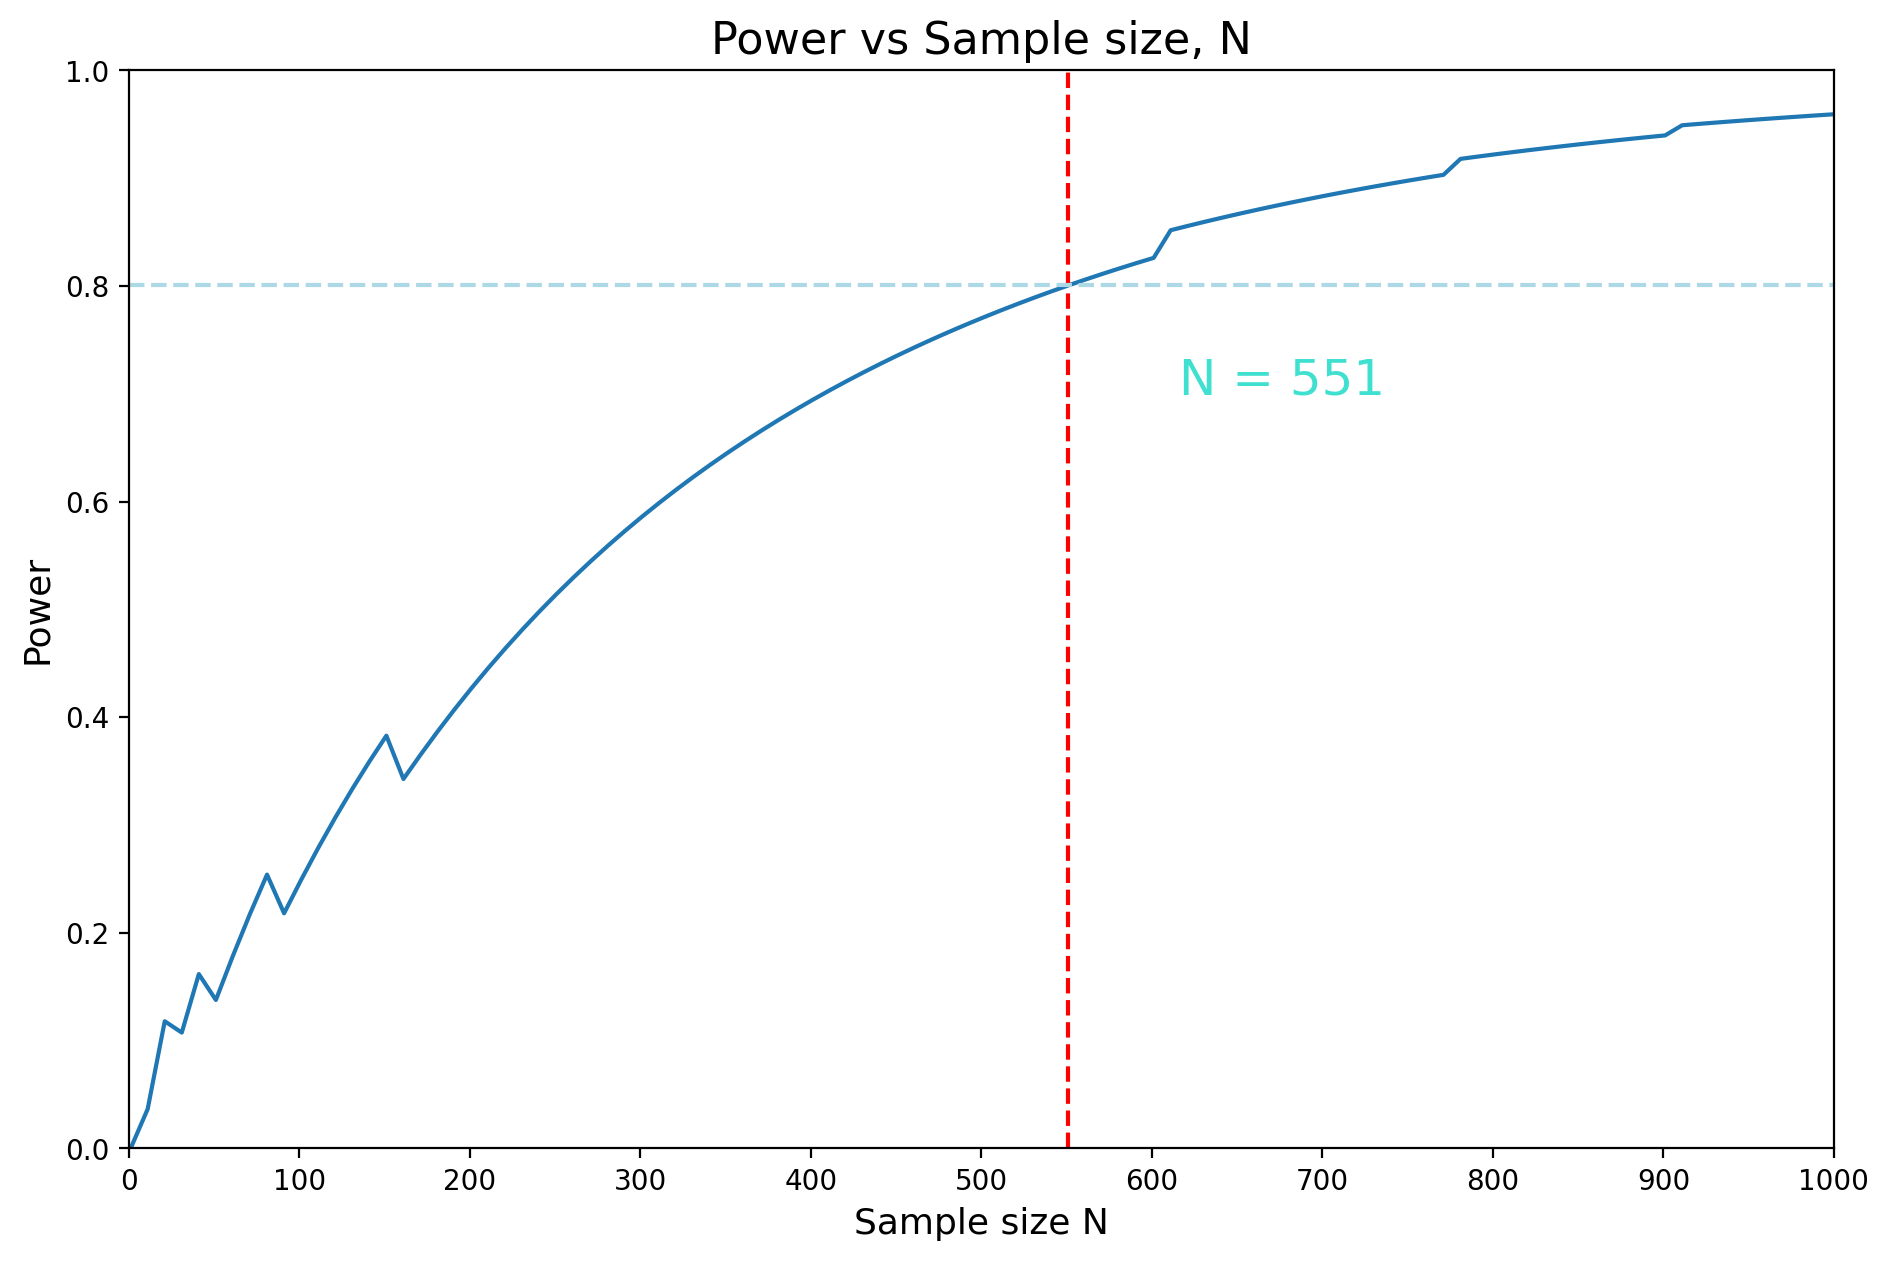

In [ ]:
# Створюємо вісь X
n_grid = np.arange(1, N + 11, 10)

# Рахуємо потужність для різних розмірів вибірки. Вісь Y
power = np.array([get_stat_power(N, mu, mu_alt, alpha) for N in range(1, N + 11, 10)])

# Рахуємо мінімальний розмір вибірки при якому power >= 0.8
min_n = n_grid[power >= 0.8].min()

# Створюємо пустий графік та додаємо графік
fig, ax = plt.subplots(figsize = (11, 7))
ax.plot(n_grid, power)

# Додаємо вертикальну та горизантальну лінії де power = 0.8
ax.axvline(min_n, color = "red", linestyle = "--")
ax.axhline(get_stat_power(min_n, mu, mu_alt, alpha), color = "lightblue", linestyle = "--")
ax.text(min_n + 65, 0.7, f"N = {min_n}", color = "turquoise", fontsize = 18)

# Задаємо заголовок, заголовки вісям, xticks, xlim, ylim
ax.set_xticks(np.arange(0, 1100, 100))
ax.set_xlabel("Sample size N", fontsize = 13)
ax.set_ylabel("Power", fontsize = 13)
ax.set_title("Power vs Sample size, N", fontsize = 16)
ax.set_xlim(0, 1000)
ax.set_ylim(0, 1)

plt.show()

**Тривалість тесту:** Компанія буде тиждень надавати знижку на наступну покупку. Тест буде закінчено доки у всіх клієнтів закінчеться знижка. Нас цікавииь RCR в період, коли клієнти могли скористатися знижкою.


**MDE:** Я вважаю ріст RCR на 5p.p. успіхом для такої маркетингової компанії, тому MDE = 0.05

**Конкретні числа:**

* Припостимо середній чек в магазині одягу 3500₴, якщо альтернативне $\mu$ = $\mu$ при знижці 10%, то ціна одного спостереження 350₴.

* Кожен клієнт, що повернувся і має 10% знижки в середньому принесе магизину 3150₴.

* Будь-яке збільшення RCR піде бізнесу на користь. Але бізнес розраховує на MDE = 0.05 та хоче знати чи збільшить ця маркетивнгова компанія RCR. Чи люди які повернуться і без знижки повернулись би і бізнес просто втрачає гроші на знижці.

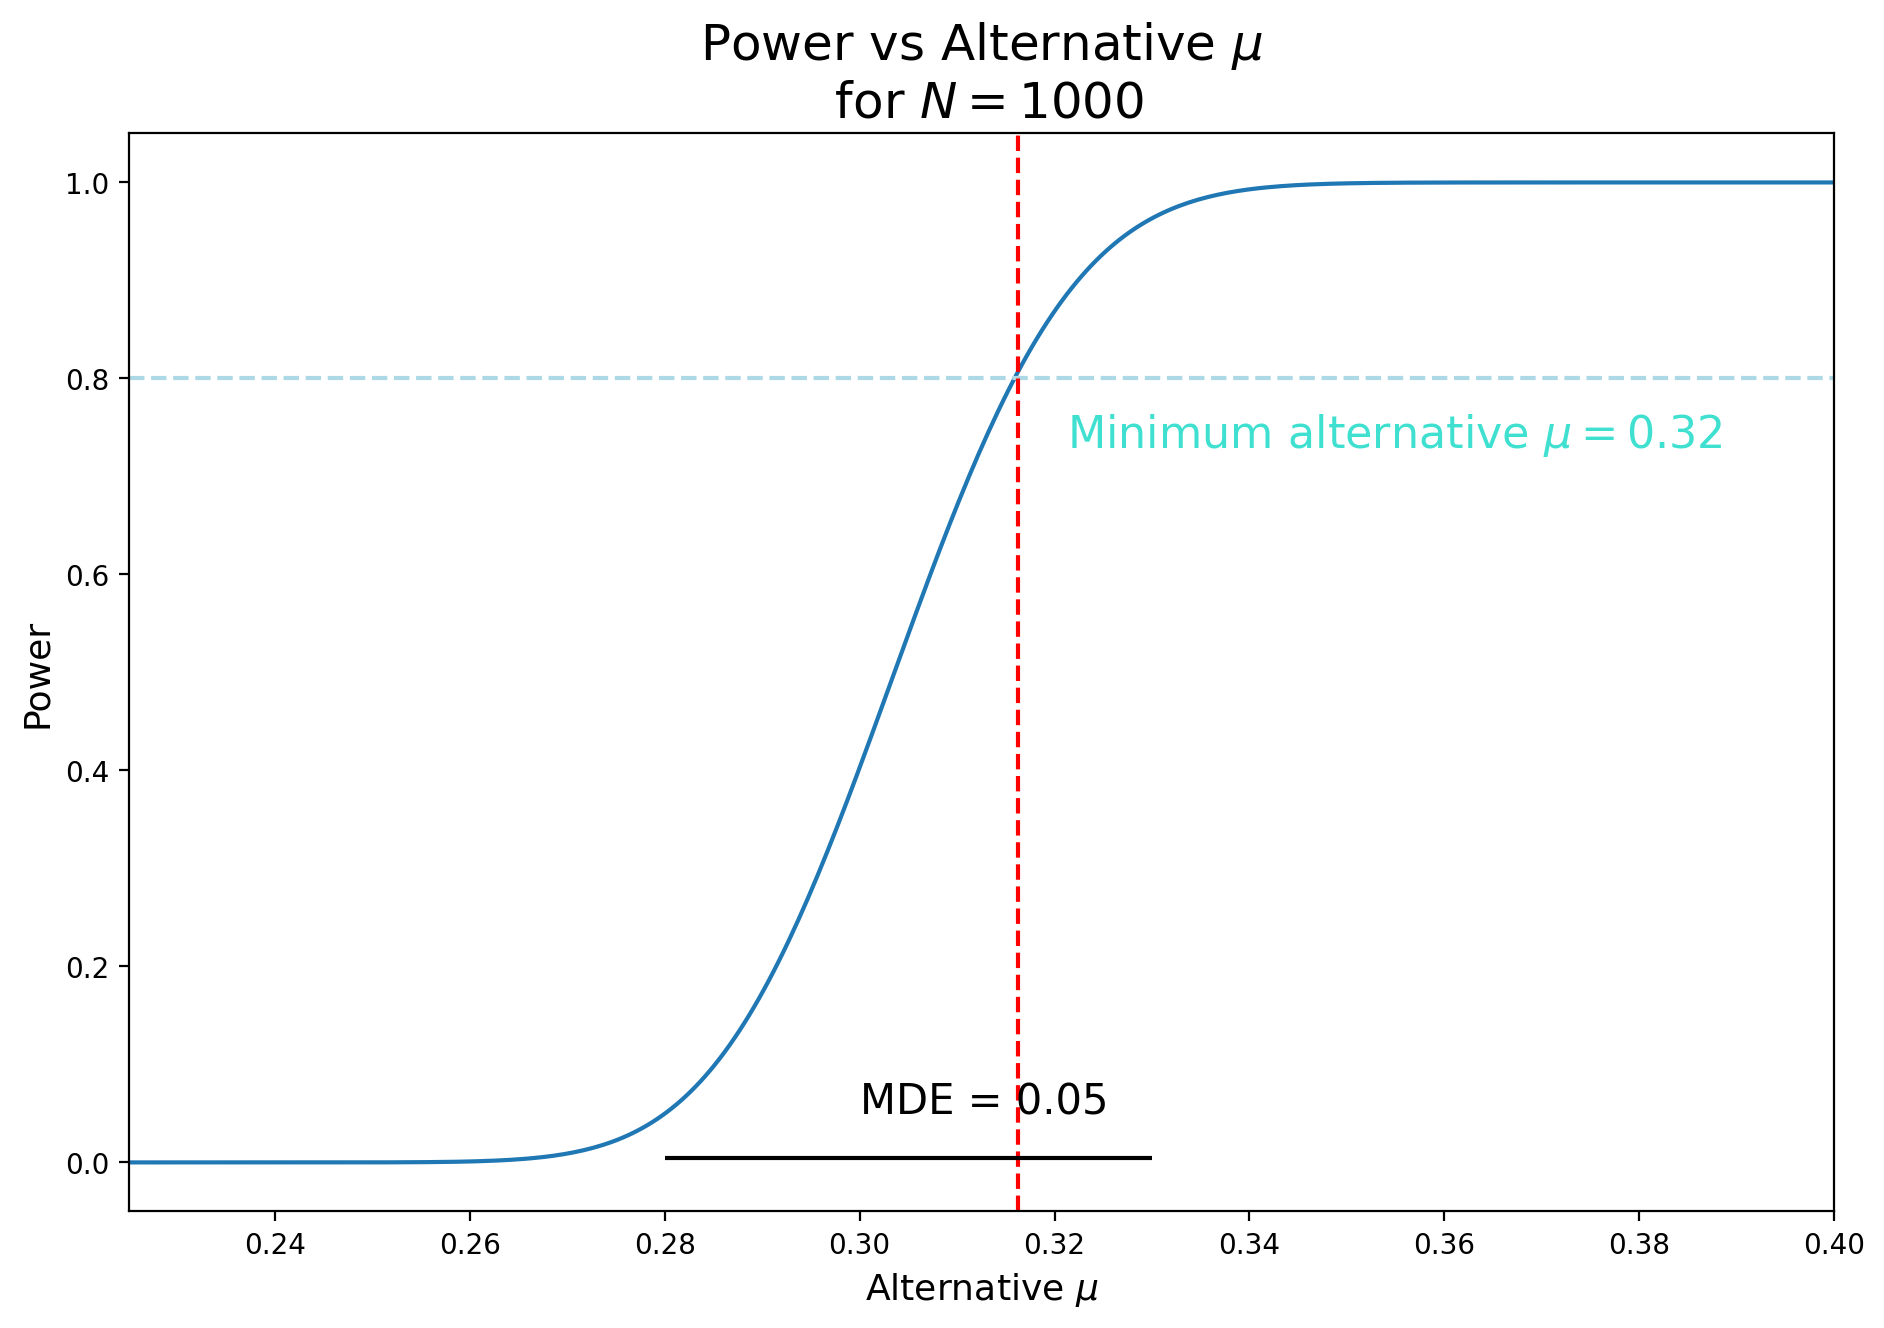

In [ ]:
# Створюємо вісь X
mu_grid = np.linspace(0.2, 0.45, 500)

# Рахуємо для потужність для різних mu_alt
power = np.array([get_stat_power(N, mu, mu_alt, alpha = alpha) for mu_alt in mu_grid])
mu_min = mu_grid[power >= 0.8].min()

# Cтворюємо пустий графік потім додаємо line plot
fig, ax = plt.subplots(figsize=(11, 7))
ax.plot(mu_grid, power)

# Додаємо вертикальну та горизантальну лінії де power = 0.8
ax.axhline(0.8, linestyle="--", color="lightblue")
ax.axvline(mu_min, linestyle="--", color="red")

ax.hlines(0.005, 0.28, 0.33, color="black")

# Створюємо текст про мінімальне альтернативне mu для power = 0.8
ax.text(mu_min + 0.005, 0.73, fr"Minimum alternative $\mu = {mu_min:.2f}$", fontsize=16, color="turquoise")
ax.text(0.3, 0.05, fr"MDE = 0.05", fontsize=15, color="black")

# Задаємо заголовок, заголовки вісям, xlim,
ax.set_title(r"Power vs Alternative $\mu$" + "\n " + r"for $N = 1000$", fontsize = 18)
ax.set_xlabel(r"Alternative $\mu$", fontsize = 13)
ax.set_ylabel("Power", fontsize = 13)
ax.set_xlim(0.225, 0.4)

plt.show()
